# <font color='red' size='6'>Inteligência Artificial</font>
### Visão Computacional: CNN, Redes pré-treinadas e Transfer Learning
#### Experimento I envolvendo CNN com TensorFlow/Keras e o dataset fashion_mnist_dataset
##### Objetivo da Atividade: pesquisar a instalação do Tensorflow/Keras, realizar a instalação e executar o código abaixo fazendo uso do modelo MobileNetV2.

#### Marcar com um X a turma a qual o grupo pertence.</br>

<b>Turma: ( &nbsp;&nbsp;&nbsp;&nbsp; )   7G</br> Turma: ( X ) 7N </b><p>
<table width="300" border="2">
    <tr>
        <td><b>Nome do Aluno</b> </td>
        <td><b>RA</b></td>
     </tr>  
   <tr>
       <td>Gabriel Ferreira </td>
       <td>10442043</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
</table>

#### Dataset: fashion_mnist_dataset
<ol type="a">
    <li>Estrutura do Dataset:</li>
    <ul>
        <li>O Fashion MNIST possui 60.000 imagens de treinamento e 10.000 imagens de teste, com 10 classes distintas.</li>
<li>Cada imagem tem o tamanho de 28x28 pixels em escala de cinza (1 canal de cor).</li>
<li>O dataset está estruturado em dois arquivos principais:</li>
        <ul>
            <li>train_images: contém as 60.000 imagens de treinamento.</li>
<li>test_images: contém as 10.000 imagens de teste.</li>
<li>train_labels: rótulos (labels) das imagens de treinamento.</li>
<li>test_labels: rótulos das imagens de teste.</li>
        </ul>
        <li>Cada imagem é associada a um rótulo de classe, que varia de 0 a 9, representando diferentes tipos de roupas.</li>
    </ul>
    <li>Estrutura do Dataset:</li>
    <ul>
        <li>As classes representam diferentes categorias de roupas, conforme listado abaixo:</li>
        <ol type="1">
            <li>T-shirt/top (camiseta)</li>
            <li>Trouser (calça)</li>
            <li>Pullover (suéter)</li>
            <li>Dress (vestido)</li>
            <li>Coat (casaco)</li>
            <li>Sandal (sandália)</li>
            <li>Shirt (camisa)</li>
            <li>Sneaker (tênis)</li>
            <li>Bag (bolsa)</li>
            <li>Ankle boot (bota)</li>
        </ol>
    </ul>
    <li>Formato das Imagens:</li>
    <ul>
    <li>As imagens possuem 28x28 pixels, com valores de intensidade de pixel variando de 0 a 255 (escala de cinza).</li>
    <li>As imagens são redimensionadas para 28x28, o que facilita o processamento e a análise. Apesar de serem simples e de baixa resolução, elas são uma boa base para testar a capacidade de um modelo de redes neurais para aprender padrões visuais.</li>
     </ul>
    <li>Objetivo do Dataset:</li>
    <ul>
    <li>O objetivo principal do Fashion MNIST é a classificação de imagens, onde o modelo precisa identificar corretamente a classe de uma imagem de roupa.</li>
    <li>Pode ser utilizado para treinar modelos de Redes Neurais Convolucionais (CNNs) e outros modelos de aprendizado de máquina, como SVMs e Árvores de Decisão.</li>
     </ul>
    <li>Pré-processamento e Normalização:</li>
    <ul>
    <li>Para melhorar a eficiência do treinamento, é comum normalizar os valores dos pixels para o intervalo [0, 1], dividindo os valores dos pixels por 255.</li>
    <li>Além disso, o dataset pode ser dividido em subconjuntos de treinamento, validação e teste, para avaliar o desempenho de modelos em diferentes estágios.</li>
     </ul>
        <li>Carregamento do Dataset:</li>
    <ul>
    <li>O Fashion MNIST pode ser carregado diretamente de bibliotecas como TensorFlow, Keras, ou PyTorch. </li>
     </ul>
</ol>

#### Referência
<p>ZALANDO RESEARCH. Fashion MNIST: A novel image dataset for benchmarking machine learning algorithms. arXiv, 2017. Disponível em: https://arxiv.org/abs/1708.07747. Acesso em: 6 mai. 2026.</p>

**Execução individual:** Gabriel Ferreira, RA 10442043. Turma 07N. Para viabilizar o experimento local, foi usada uma amostra estratificada e reproduzível de 200 imagens por classe no treino e 50 por classe na validação e no teste. As amostras de teste são disjuntas do treino. Resultados não representam o desempenho no conjunto completo.


In [1]:
"""
Classificador de roupas reais com Transfer Learning (MobileNetV2) usando TensorFlow/Keras.
Inclui treino, validação, teste, gráficos e matriz de confusão.

OBSERVAÇÃO: Faça mudanças no número de épocas e verifique o melhor resultado.
"""

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
tf.keras.utils.set_random_seed(10442043)


In [2]:
IMG_SIZE = (96, 96)
BATCH_SIZE = 32
EPOCHS = 5

In [3]:
from pathlib import Path
from zipfile import ZipFile
if not Path('fashion_mnist_amostra').exists():
    with ZipFile('dados_experimentos_cnn.zip') as archive:
        archive.extractall('.')
train_ds = tf.keras.utils.image_dataset_from_directory('fashion_mnist_amostra/train', image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=True, seed=43)
val_ds = tf.keras.utils.image_dataset_from_directory('fashion_mnist_amostra/val', image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory('fashion_mnist_amostra/test', image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False)

Found 2000 files belonging to 10 classes.


Found 500 files belonging to 10 classes.


Found 500 files belonging to 10 classes.


In [4]:
class_names = train_ds.class_names
num_classes = len(class_names)

In [5]:
# Otimização de desempenho com prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [6]:
# Modelo com MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Congela a base

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])


In [8]:
# Compilação do modelo
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
model.save('model_mobilenetv2.keras')
model = tf.keras.models.load_model('model_mobilenetv2.keras')
print('Modelo salvo e carregado.')

Epoch 1/5


/Users/wvxbs/Documents/repos/faculdade/inteligencia-artificial/.venv-cnn/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/63 ━━━━━━━━━━━━━━━━━━━━ 1:13 1s/step - accuracy: 0.0938 - loss: 3.1993

 4/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.2344 - loss: 2.6220

 7/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3482 - loss: 2.1879

10/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3875 - loss: 2.0031

... (121 outputs left out)

58/63 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9289 - loss: 0.2021

61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9293 - loss: 0.2012

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9280 - loss: 0.2036 - val_accuracy: 0.8680 - val_loss: 0.3799


Modelo salvo e carregado.


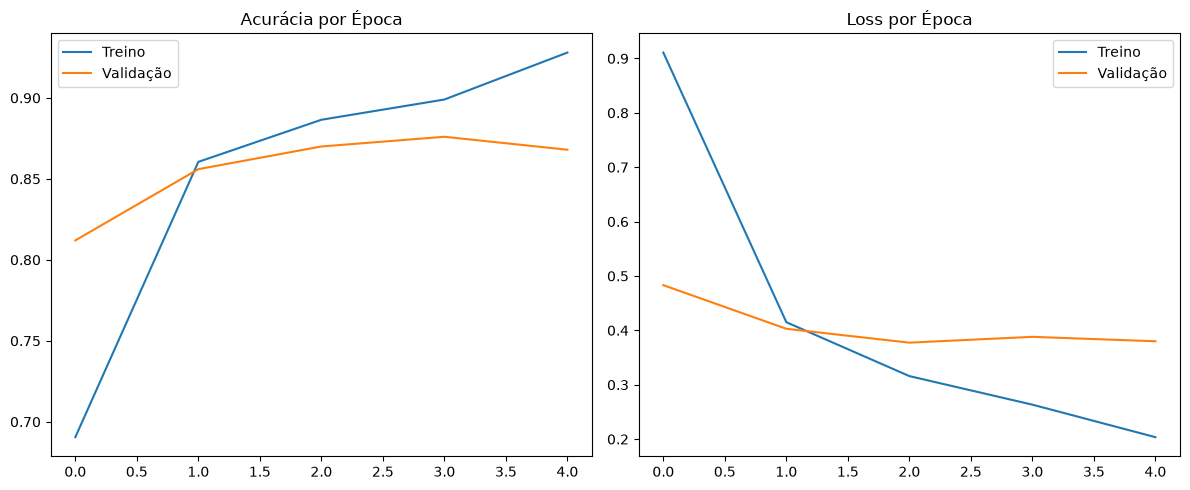

In [10]:
# Plot de loss e acurácia
def plot_metrics(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Treino')
    plt.plot(epochs_range, val_acc, label='Validação')
    plt.title('Acurácia por Época')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Treino')
    plt.plot(epochs_range, val_loss, label='Validação')
    plt.title('Loss por Época')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_metrics(history)

In [11]:
# Avaliação no conjunto de teste
test_loss, test_acc = model.evaluate(test_ds)
print(f"Acurácia no conjunto de teste: {test_acc:.2f}")

 1/16 ━━━━━━━━━━━━━━━━━━━━ 8s 548ms/step - accuracy: 0.9688 - loss: 0.2604

 3/16 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9688 - loss: 0.1998 

 5/16 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9125 - loss: 0.3066

 8/16 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9023 - loss: 0.3344

11/16 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8636 - loss: 0.4467

14/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8527 - loss: 0.4706

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8620 - loss: 0.4438


Acurácia no conjunto de teste: 0.86


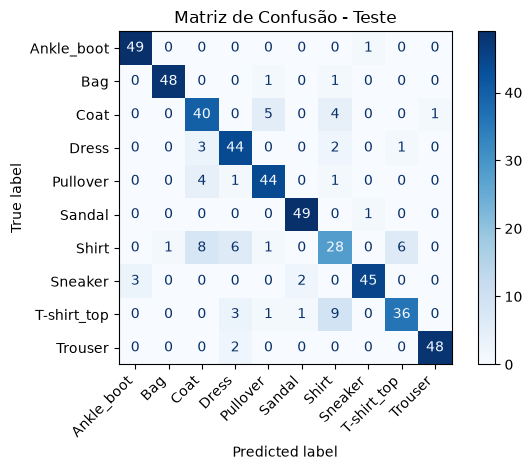

In [12]:
y_true, y_pred = [], []
for images, labels in test_ds:
    preds = model(images, training=False).numpy()
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.xticks(rotation=45, ha='right')
plt.title('Matriz de Confusão - Teste')
plt.tight_layout()
plt.show()

### <font size = '2'>prof. Dr. Ivan Carlos Alcântara de Oliveira</font> - <font color="blue" size = '2'>https://orcid.org/0000-0002-6020-7535.</font><br><font size = '2'> e-mail: ivan.oliveira@mackenzie.br</font>

In [13]:
import json
from pathlib import Path
results = {'model': 'MobileNetV2', 'epochs': EPOCHS, 'classes': class_names, 'train_loss': history.history['loss'], 'val_loss': history.history['val_loss'], 'train_acc': history.history['accuracy'], 'val_acc': history.history['val_accuracy'], 'test_accuracy': float(test_acc), 'confusion_matrix': cm.tolist()}
Path('resultados_mobilenetv2.json').write_text(json.dumps(results, ensure_ascii=False, indent=2))
print('Métricas salvas.')


Métricas salvas.
